In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
df = pd.read_csv(os.path.join("..", "datos", "credit_risk_dataset.csv"))

## Manejo de datos faltantes

In [3]:
df_limpio = df.copy()

faltantes = pd.DataFrame({
    "faltantes": df_limpio.isna().sum(),
    "porcentaje": (df_limpio.isna().mean() * 100).round(2),
})
faltantes = faltantes[faltantes["faltantes"] > 0]
print(faltantes)

cols_nulos = faltantes.index.tolist()
print("\nFilas con al menos un faltante:", df_limpio.isna().any(axis=1).sum())
print("Filas con ambos faltantes:", df_limpio[cols_nulos].isna().all(axis=1).sum())

                   faltantes  porcentaje
person_emp_length        895        2.75
loan_int_rate           3116        9.56

Filas con al menos un faltante: 3943
Filas con ambos faltantes: 68


In [5]:
edades_raras = (df["person_age"] > 100).sum()
antig_rara = (df["person_emp_length"] > 60).sum()
print(f"Personas con edad mayor a 100 años: {edades_raras}")
print(f"Personas con más de 60 años de antigüedad laboral: {antig_rara}")
 
df_limpio.loc[df_limpio["person_age"] > 100, "person_age"] = np.nan
df_limpio.loc[df_limpio["person_emp_length"] > 60, "person_emp_length"] = np.nan
print("\nEstos valores imposibles se convirtieron en datos faltantes (NaN).")

Personas con edad mayor a 100 años: 5
Personas con más de 60 años de antigüedad laboral: 2

Estos valores imposibles se convirtieron en datos faltantes (NaN).


In [6]:
#Imputar los datos
df_limpio["loan_int_rate"] = df_limpio["loan_int_rate"].fillna(
    df_limpio.groupby("loan_grade")["loan_int_rate"].transform("median"))

df_limpio["person_emp_length"] = df_limpio["person_emp_length"].fillna(
    df_limpio.groupby("person_home_ownership")["person_emp_length"].transform("median"))

df_limpio["person_age"] = df_limpio["person_age"].fillna(df_limpio["person_age"].median())

# Resultado después de imputar
print("Datos faltantes por columna después de imputar:")
print(df_limpio.isna().sum())
print("\nTotal de datos faltantes:", df_limpio.isna().sum().sum())

print("\nPrimeras 5 filas del dataframe limpio:")
print(df_limpio.head())

# Filas que originalmente tenían un dato faltante, ya imputadas
filas_imputadas = df.index[df["loan_int_rate"].isna() | df["person_emp_length"].isna()]
comparacion = pd.DataFrame({
    "tasa_original": df.loc[filas_imputadas, "loan_int_rate"],
    "tasa_imputada": df_limpio.loc[filas_imputadas, "loan_int_rate"],
    "antig_original": df.loc[filas_imputadas, "person_emp_length"],
    "antig_imputada": df_limpio.loc[filas_imputadas, "person_emp_length"],
    "calificacion": df_limpio.loc[filas_imputadas, "loan_grade"],
    "vivienda": df_limpio.loc[filas_imputadas, "person_home_ownership"],
})


print("\nDimensiones del dataframe limpio:", df_limpio.shape)

Datos faltantes por columna después de imputar:
person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64

Total de datos faltantes: 0

Primeras 5 filas del dataframe limpio:
   person_age  person_income person_home_ownership  person_emp_length  \
0        22.0          59000                  RENT                3.0   
1        21.0           9600                   OWN                5.0   
2        25.0           9600              MORTGAGE                1.0   
3        23.0          65500                  RENT                4.0   
4        24.0          54400                  RENT                8.0   

  loan_intent loan_grade  loan_amnt  loan_int_r

                   Faltantes  Porcentaje (%)
person_emp_length        895            2.75
loan_int_rate           3116            9.56


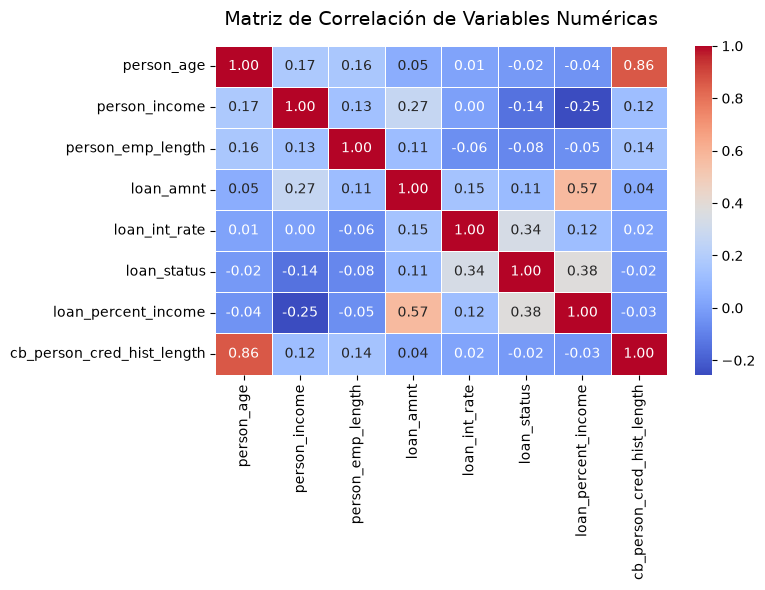

In [10]:
corr_matrix = df.select_dtypes(include=['number']).corr()
nulos_df = pd.DataFrame(
    {
        'Faltantes': df.isnull().sum(),
        'Porcentaje (%)': (df.isnull().mean() * 100).round(2),
    }
)
print(nulos_df[nulos_df['Faltantes'] > 0])

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5
)
plt.title('Matriz de Correlación de Variables Numéricas', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

## Valores inconsistentes y duplicados

In [ ]:
# Valores inconsistentes en texto
cols_texto = df_limpio.select_dtypes(include=["object", "string"]).columns.tolist()
print("Columnas de texto:", cols_texto)

# Categorías antes de limpiar
for col in cols_texto:
    print(f"\n{col}: {df_limpio[col].nunique()} categorías")
    print(df_limpio[col].value_counts(dropna=False))

Columnas de texto: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

person_home_ownership: 4 categorías
person_home_ownership
RENT        16446
MORTGAGE    13444
OWN          2584
OTHER         107
Name: count, dtype: int64

loan_intent: 6 categorías
loan_intent
EDUCATION            6453
MEDICAL              6071
VENTURE              5719
PERSONAL             5521
DEBTCONSOLIDATION    5212
HOMEIMPROVEMENT      3605
Name: count, dtype: int64

loan_grade: 7 categorías
loan_grade
A    10777
B    10451
C     6458
D     3626
E      964
F      241
G       64
Name: count, dtype: int64

cb_person_default_on_file: 2 categorías
cb_person_default_on_file
N    26836
Y     5745
Name: count, dtype: int64


In [15]:
#Estandarizacion de el dataframe
antes = df_limpio[cols_texto].copy()

for col in cols_texto:
    df_limpio[col] = df_limpio[col].str.strip().str.upper()

cambios = (antes != df_limpio[cols_texto]).sum()
print("Valores modificados por columna al estandarizar:")
print(cambios)

Valores modificados por columna al estandarizar:
person_home_ownership        0
loan_intent                  0
loan_grade                   0
cb_person_default_on_file    0
dtype: int64


In [17]:
##Analisis de los  duplicados
filas_antes = len(df_limpio)
n_duplicados = df_limpio.duplicated().sum()
print(f"Filas duplicadas exactas: {n_duplicados} "
      f"({n_duplicados / filas_antes * 100:.2f}%)")

Filas duplicadas exactas: 0 (0.00%)


In [18]:
## Eliminar duplicados
df_limpio = df_limpio.drop_duplicates(keep="first")

print(f"\nFilas antes:   {filas_antes}")
print(f"Filas después: {len(df_limpio)}")
print(f"Filas eliminadas: {filas_antes - len(df_limpio)}")
print("Duplicados restantes:", df_limpio.duplicated().sum())

print("\nLa decisión es eliminar los duplicados exactos: son registros repetidos "
      "del mismo préstamo y dejarlos sesgaría el análisis y los modelos.")
print("Dimensiones de df_limpio:", df_limpio.shape)


Filas antes:   32416
Filas después: 32416
Filas eliminadas: 0
Duplicados restantes: 0

La decisión es eliminar los duplicados exactos: son registros repetidos del mismo préstamo y dejarlos sesgaría el análisis y los modelos.
Dimensiones de df_limpio: (32416, 12)


## Nuevas Variables

In [ ]:
df_limpio['historial_vs_edad'] = df['cb_person_cred_hist_length'] / df['person_age']
df_limpio['interes_estimado'] = df['loan_amnt'] * (df['loan_int_rate'] / 100)

## Filtrado y condiciones en pandas

In [28]:
# Filtrado y condiciones en pandas
tasa_global = df_limpio["loan_status"].mean() * 100
print(f"Tasa de incumplimiento global: {tasa_global:.2f}%")

Tasa de incumplimiento global: 21.82%


In [30]:
#  1. Préstamos con interés estimado muy alto (percentil 90) 
p90 = df_limpio["interes_estimado"].quantile(0.90)
f1 = df_limpio[df_limpio["interes_estimado"] > p90]
tasa1 = f1["loan_status"].mean() * 100
print(f"\n1) Interés estimado > {p90:,.0f}: {len(f1)} préstamos, incumplimiento {tasa1:.2f}%")
print(f"   Conclusión: los préstamos con mayor costo en intereses incumplen "
      f"{'más' if tasa1 > tasa_global else 'menos'} que el promedio ({tasa_global:.2f}%).")


1) Interés estimado > 2,292: 2946 préstamos, incumplimiento 41.21%
   Conclusión: los préstamos con mayor costo en intereses incumplen más que el promedio (21.82%).


In [31]:
#  2. Historial crediticio largo respecto a la edad 
f2 = df_limpio[df_limpio["historial_vs_edad"] > 0.30]
tasa2 = f2["loan_status"].mean() * 100
print(f"\n2) Historial > 30% de la edad: {len(f2)} personas, incumplimiento {tasa2:.2f}%")
print(f"   Conclusión: tener un historial largo para su edad "
      f"{'no reduce' if tasa2 >= tasa_global else 'reduce'} el incumplimiento frente al promedio.")


2) Historial > 30% de la edad: 5260 personas, incumplimiento 21.18%
   Conclusión: tener un historial largo para su edad reduce el incumplimiento frente al promedio.


In [32]:
# 3. Registros inconsistentes (edad o historial imposibles) 
f3 = df_limpio[(df_limpio["person_age"] > 100) |
               (df_limpio["historial_vs_edad"] >= 1) |
               (df_limpio["person_emp_length"] > df_limpio["person_age"] - 14)]
print(f"\n3) Registros con edad/antigüedad/historial imposibles: {len(f3)}")
print(f3[["person_age", "person_emp_length", "cb_person_cred_hist_length"]].head())
print("   Conclusión: son errores de captura que conviene revisar o excluir antes de modelar.")


3) Registros con edad/antigüedad/historial imposibles: 7
     person_age  person_emp_length  cb_person_cred_hist_length
0            22              123.0                           3
81          144                4.0                           3
183         144                4.0                           2
210          21              123.0                           4
575         123                2.0                           3
   Conclusión: son errores de captura que conviene revisar o excluir antes de modelar.


In [34]:
# 4. Arrendatarios con carga alta sobre el ingreso 
f4 = df_limpio[(df_limpio["person_home_ownership"] == "RENT") &
               (df_limpio["loan_percent_income"] > 0.40)]
tasa4 = f4["loan_status"].mean() * 100
print(f"\n4) RENT y préstamo > 40% del ingreso: {len(f4)} personas, incumplimiento {tasa4:.2f}%")
print(f"   Conclusión: quienes arriendan y deben mucho respecto a su ingreso "
      f"tienen incumplimiento de {tasa4:.2f}%, {'superior' if tasa4 > tasa_global else 'inferior'} al global.")


4) RENT y préstamo > 40% del ingreso: 716 personas, incumplimiento 100.00%
   Conclusión: quienes arriendan y deben mucho respecto a su ingreso tienen incumplimiento de 100.00%, superior al global.


In [35]:
# 5. Historial corto y monto de préstamo alto 
mediana_monto = df_limpio["loan_amnt"].median()
f5 = df_limpio[(df_limpio["historial_vs_edad"] < 0.10) &
               (df_limpio["loan_amnt"] > mediana_monto)]
tasa5 = f5["loan_status"].mean() * 100
dif5 = tasa5 - tasa_global
print(f"\n5) Historial < 10% de la edad y monto > {mediana_monto:,.0f}: {len(f5)} préstamos, incumplimiento {tasa5:.2f}%")
print(f"   Conclusión: la tasa de incumplimiento de este grupo es {tasa5:.2f}% frente a "
      f"{tasa_global:.2f}% del total, es decir, {abs(dif5):.2f} puntos "
      f"{'por encima' if dif5 > 0 else 'por debajo'} de la tasa global. "
      f"{'Pedir montos altos con poca trayectoria crediticia es más riesgoso que el promedio.' if dif5 > 0 else 'Pedir montos altos con poca trayectoria crediticia es menos riesgoso que el promedio.'}")


5) Historial < 10% de la edad y monto > 8,000: 2778 préstamos, incumplimiento 26.53%
   Conclusión: la tasa de incumplimiento de este grupo es 26.53% frente a 21.82% del total, es decir, 4.71 puntos por encima de la tasa global. Pedir montos altos con poca trayectoria crediticia es más riesgoso que el promedio.


## Visualizaciones

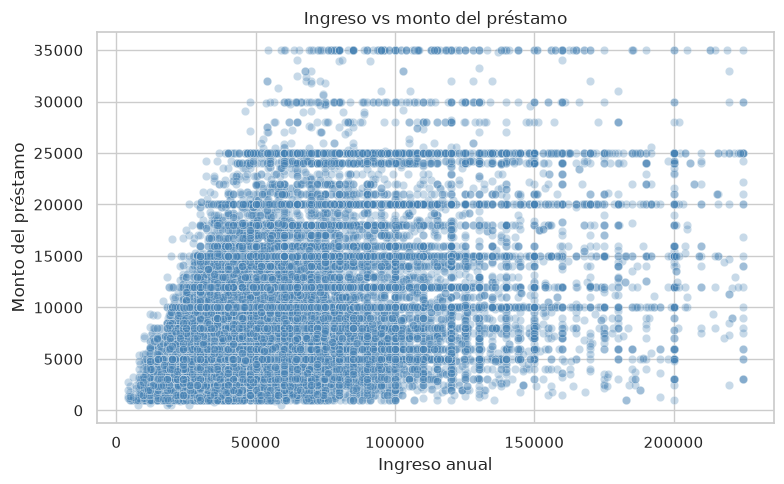

Conclusión: la correlación entre ingreso y monto es 0.27, una relación débil: el monto pedido casi no depende del ingreso.


In [38]:
sns.set_theme(style="whitegrid")
# 1. DISPERSIÓN: ingreso vs monto del préstamo 
muestra = df_limpio[df_limpio["person_income"] < df_limpio["person_income"].quantile(0.99)]
plt.figure(figsize=(8, 5))
sns.scatterplot(data=muestra, x="person_income", y="loan_amnt", alpha=0.3, color="steelblue")
plt.title("Ingreso vs monto del préstamo")
plt.xlabel("Ingreso anual")
plt.ylabel("Monto del préstamo")
plt.tight_layout()
plt.show()

corr1 = df_limpio["person_income"].corr(df_limpio["loan_amnt"])
print(f"Conclusión: la correlación entre ingreso y monto es {corr1:.2f}, "
      f"{'una relación positiva moderada: quien gana más tiende a pedir más.' if corr1 > 0.3 else 'una relación débil: el monto pedido casi no depende del ingreso.'}")

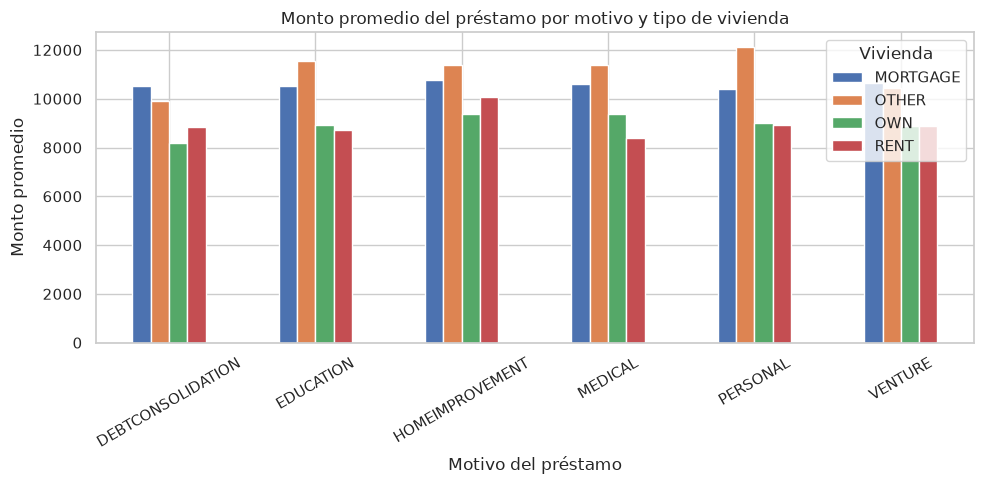

Conclusión: el motivo con mayor monto promedio es HOMEIMPROVEMENT (10,361) y el de menor monto es MEDICAL (9,260).


In [39]:
# 2. BARRAS AGRUPADAS: monto promedio por motivo y tipo de vivienda
tabla2 = df_limpio.groupby(["loan_intent", "person_home_ownership"])["loan_amnt"].mean().unstack()
tabla2.plot(kind="bar", figsize=(10, 5))
plt.title("Monto promedio del préstamo por motivo y tipo de vivienda")
plt.xlabel("Motivo del préstamo")
plt.ylabel("Monto promedio")
plt.xticks(rotation=30)
plt.legend(title="Vivienda")
plt.tight_layout()
plt.show()

prom2 = df_limpio.groupby("loan_intent")["loan_amnt"].mean()
print(f"Conclusión: el motivo con mayor monto promedio es {prom2.idxmax()} ({prom2.max():,.0f}) "
      f"y el de menor monto es {prom2.idxmin()} ({prom2.min():,.0f}).")

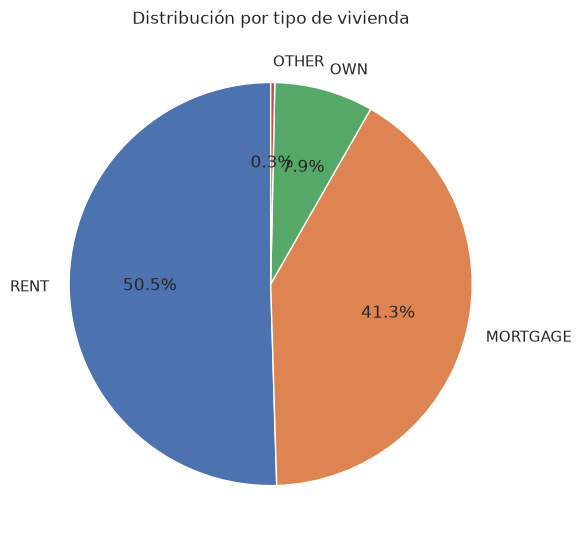

Conclusión: RENT es el tipo de vivienda más común (50.5% de las personas) y OTHER el menos común (0.3%).


In [40]:
# 3. CIRCULAR: distribución por tipo de vivienda
conteo3 = df_limpio["person_home_ownership"].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(conteo3, labels=conteo3.index, autopct="%1.1f%%", startangle=90)
plt.title("Distribución por tipo de vivienda")
plt.tight_layout()
plt.show()

print(f"Conclusión: {conteo3.index[0]} es el tipo de vivienda más común "
      f"({conteo3.iloc[0] / conteo3.sum() * 100:.1f}% de las personas) y "
      f"{conteo3.index[-1]} el menos común ({conteo3.iloc[-1] / conteo3.sum() * 100:.1f}%).")

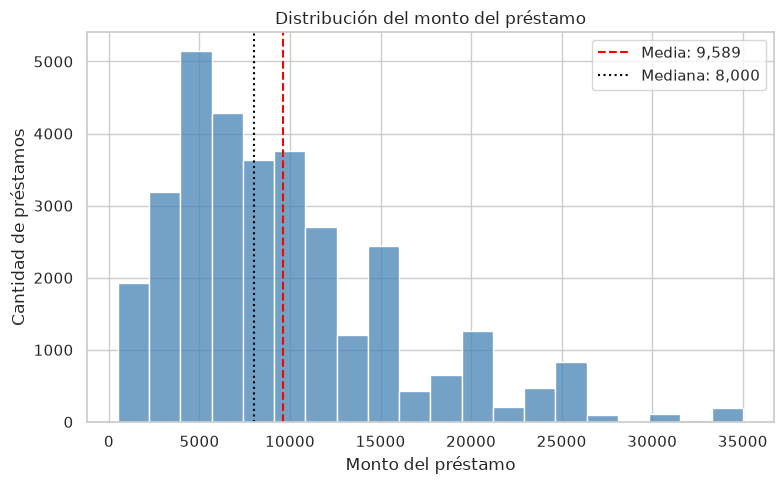

Conclusión: el monto promedio es 9,589 y la mediana 8,000. El rango más frecuente es 3,950 a 5,675. La media supera a la mediana, así que unos pocos préstamos grandes jalan el promedio hacia arriba.


In [44]:
# 4. Histograma: distribución del monto del préstamo
media4 = df_limpio["loan_amnt"].mean()
mediana4 = df_limpio["loan_amnt"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df_limpio, x="loan_amnt", bins=20, color="steelblue")
plt.axvline(media4, color="red", linestyle="--", label=f"Media: {media4:,.0f}")
plt.axvline(mediana4, color="black", linestyle=":", label=f"Mediana: {mediana4:,.0f}")
plt.title("Distribución del monto del préstamo")
plt.xlabel("Monto del préstamo")
plt.ylabel("Cantidad de préstamos")
plt.legend()
plt.tight_layout()
plt.show()

rango = pd.cut(df_limpio["loan_amnt"], bins=20).value_counts().idxmax()
print(f"Conclusión: el monto promedio es {media4:,.0f} y la mediana {mediana4:,.0f}. "
      f"El rango más frecuente es {rango.left:,.0f} a {rango.right:,.0f}. "
      f"{'La media supera a la mediana, así que unos pocos préstamos grandes jalan el promedio hacia arriba.' if media4 > mediana4 else 'La media y la mediana son parecidas, así que los montos están repartidos de forma bastante simétrica.'}")

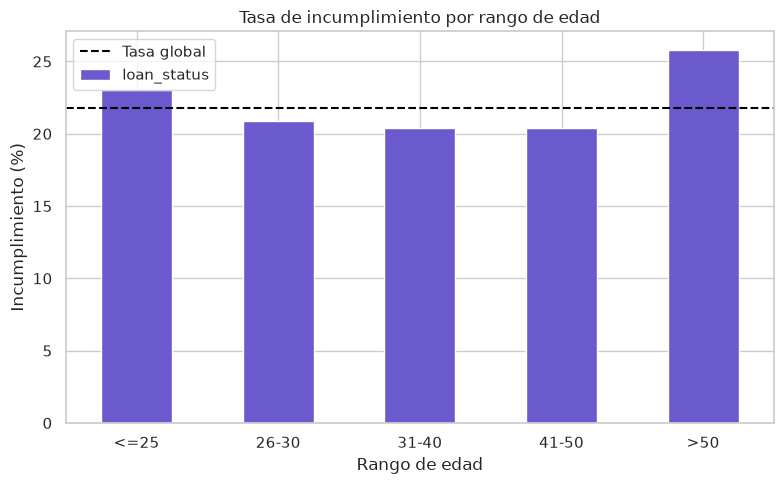

Conclusión: el rango >50 tiene el mayor incumplimiento (25.80%) y el rango 31-40 el menor (20.37%), con 21.82% a nivel global. La diferencia entre edades es de 5.42 puntos.


In [45]:
# 5. BARRAS: incumplimiento por rango de edad 
df_limpio["rango_edad"] = pd.cut(df_limpio["person_age"], bins=[0, 25, 30, 40, 50, 120],
                                 labels=["<=25", "26-30", "31-40", "41-50", ">50"])
tasa5 = df_limpio.groupby("rango_edad", observed=True)["loan_status"].mean().mul(100)
plt.figure(figsize=(8, 5))
tasa5.plot(kind="bar", color="slateblue")
plt.axhline(tasa_global, color="black", linestyle="--", label="Tasa global")
plt.title("Tasa de incumplimiento por rango de edad")
plt.xlabel("Rango de edad")
plt.ylabel("Incumplimiento (%)")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Conclusión: el rango {tasa5.idxmax()} tiene el mayor incumplimiento ({tasa5.max():.2f}%) "
      f"y el rango {tasa5.idxmin()} el menor ({tasa5.min():.2f}%), con {tasa_global:.2f}% a nivel global. "
      f"La diferencia entre edades es de {tasa5.max() - tasa5.min():.2f} puntos.")